this is one of my data science project, in this project i try to analyze depression status based on other variable

In [1]:
import os

for dirname, subdirs, filenames in os.walk('/kaggle/input'):
    print(f"\nFolder: {dirname}")

    for filename in filenames:
        print(f"  File: {filename}")


Folder: /kaggle/input

Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/mkhoirulmustaqim

Folder: /kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset

Folder: /kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset/Student Depression Detection Dataset
  File: Student_Depression_Dataset.csv
  File: Student_Depression_Dataset.xlsx


in this part use to find out the directory, the directory use to get the dataset into dataframe

In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

file_path = '/kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset/Student Depression Detection Dataset/Student_Depression_Dataset.csv'

data_frame = pd.read_csv(file_path)

import some libraries, and load the data

In [3]:
display(data_frame.head())

display(data_frame.tail())

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


check the data, this show first 5 row and the last 5 row of dataset

In [4]:
data_frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


i used to do this to find out the missing value, if yes i will do the treatment (remove or change it)

In [5]:
data_frame.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [6]:
data_frame.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [7]:
columns = data_frame.columns.tolist()

for column in columns:
    print (data_frame[column].value_counts())

Gender
Female    2462
Male      2002
Name: count, dtype: int64
Age
23    1161
21     726
22     614
25     523
20     513
24     430
26     187
18      86
27      83
19      65
28      62
17      14
Name: count, dtype: int64
Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64
Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64
Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64
Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64
Current_semester
5     752
4     553
2     543
8     511
3     511
6     500
7     404
9     286
11    119
10    114
1      88
0      42
12     40
13      1
Name: count, dtype: int64
CGPA
3.00    280
3.60    142
3.50    135
4.00    130
3.89    130
       ... 
2.29      1
2.43      1
2.47      1
2.48      1
2.42      1
Name: count, Length: 169, dtype: int64

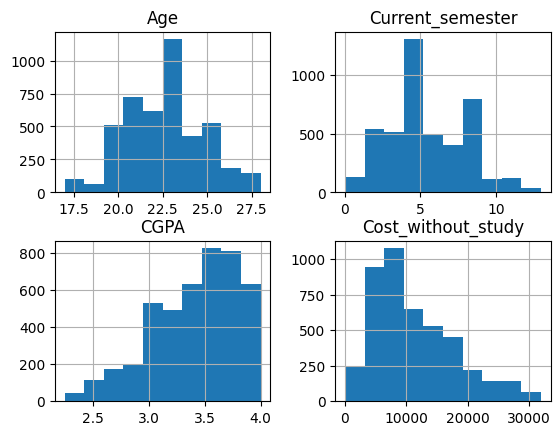

In [8]:
data_frame.hist()
plt.show()

In [9]:


df_encoded = data_frame.copy()

binary_mapping = {
    'Gender': {'Female': 0, 'Male': 1},
    'Living_style': {'Bachelor': 0, 'Family': 1},
    'friend_circle': {'No': 0, 'Yes': 1},
    'Depression': {'No': 0, 'Yes': 1}
}

for column, mapping in binary_mapping.items():
    df_encoded[column] = df_encoded[column].map(mapping)


ordinal_mapping = {
    'Family_background': {
        'Lower Middle class': 1,
        'Middle class': 2,
        'Rich class': 3
    },
    'Health_condition': {
        'Abnormal': 1,
        'Critical': 2,
        'Normal': 3,
        'Good': 4
    }
}

for column, mapping in ordinal_mapping.items():
    df_encoded[column] = df_encoded[column].map(mapping)


categorical_columns = [
    'Relationship_status',
    'Marital_status',
    'Home_division'
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)


print("=== DATAFRAME SETELAH ENCODING ===")
print(df_encoded.head())

print("\n=== INFORMASI DATAFRAME ===")
df_encoded.info()

print("\n=== CEK MISSING VALUES ===")
print(df_encoded.isnull().sum())

print("\n=== TIPE DATA ===")
print(df_encoded.dtypes)


=== DATAFRAME SETELAH ENCODING ===
   Gender  Age  Family_background  Living_style  Current_semester  CGPA  \
0       0   22                  2             0                 8  3.43   
1       1   19                  2             0                 2  3.70   
2       1   23                  2             1                 8  3.28   
3       1   20                  2             1                 2  3.77   
4       0   21                  2             1                 1  4.00   

   friend_circle  Health_condition  Cost_without_study  Depression  ...  \
0              1                 2               10113           1  ...   
1              1                 1               13815           1  ...   
2              0                 1               15450           1  ...   
3              0                 4               17413           0  ...   
4              0                 1               16693           1  ...   

   Relationship_status_Single  Marital_status_Separated  \
0   